# MX057 — Offline Calibration Backtest

## tl;dr
This is a read-only historical replay: 62 source days from 12 May to 9 Aug 2026, with 7–9 Aug reserved as a forward-only shadow period. The partial 10 Aug export is excluded. No Server, MySQL analytics table, Active Profile or machine-control path was used.

The current replay applies the owner-confirmed Cold gate: Compressor ON, `Status_n=On`, `Busy=0`, and `SV=Off`. The result is a calibration-gate test, never a fault conclusion.

## Context & Methods

**Grain:** raw one-second handler logs are aggregated to stable one-minute windows. **Timezone assumption:** Asia/Bangkok; source exports do not encode a timezone. **Profile key:** Machine × Module × SV × qualified state. **Current eligible state:** Compressor ON + `Status_n=On` + `Busy=0` + `SV=Off`. The candidate fits median/MAD-style robust local statistics on history, then shadows the final three days. Red points only mean score above a local candidate threshold; they are not confirmed equipment faults.

### Key assumption
The 28-day gap between the May and late-June extracts is retained as a provenance limitation; it is not imputed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

artifact = Path('outputs/mx057_offline_calibration_backtest_v4_confirmed_state')
summary = json.loads((artifact / 'summary.json').read_text(encoding='utf-8'))
profiles = pd.read_csv(artifact / 'profile_summary.csv')
summary

{'scope': {'machine': 'MX057',
  'timezone_assumption': 'Asia/Bangkok',
  'source_days': 62,
  'source_start': '2026-05-12',
  'source_end_exclusive': '2026-08-10',
  'shadow_start': '2026-08-07',
  'shadow_end': '2026-08-09'},
 'quality': {'raw_rows': 5263827,
  'duplicate_machine_minutes': 0,
  'qualified_minutes': 505471,
  'qualified_days': 54},
 'profiles': {'total': 7,
  'by_status': {'CANDIDATE_PROFILE': 5, 'REVIEW_REQUIRED': 2},
  'approval_dry_run_eligible': 0},
 'boundary': {'operation': 'APPROVAL_DRY_RUN_ONLY',
  'actual_server_or_database_activation': False,
  'eligible_profile_keys': [],
  'not_eligible_count': 7}}

## Data quality and profile gates

In [2]:
display(profiles[['module','sv_state','status','reasons','calibration_windows','shadow_windows',
                  'quarantine_pct','shadow_flag_pct','persistent_flag_pct','shadow_elapsed_hours']])

,module,sv_state,status,reasons,calibration_windows,shadow_windows,quarantine_pct,shadow_flag_pct,persistent_flag_pct,shadow_elapsed_hours
0,1,Off,REVIEW_REQUIRED,QUARANTINE_RATE_EXCEEDED;SHADOW_DURATION_LT_RE...,68332,3849,5.326933,0.623539,0.571577,64.133333
1,2,Off,REVIEW_REQUIRED,SHADOW_DURATION_LT_REQUIRED;SHADOW_FLAG_RATE_E...,68356,3850,0.241383,3.272727,2.805195,64.150000
2,3,Off,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED,68390,3849,1.137593,0.389712,0.337750,64.133333
3,4,Off,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED,68329,3848,0.295629,0.415800,0.363825,64.116667
4,5,Off,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED,68371,3848,1.133522,0.519751,0.467775,64.116667
5,6,Off,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED,68369,3848,1.159882,0.285863,0.233888,64.116667
6,8,Off,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED,68382,3850,0.304174,0.649351,0.597403,64.150000


## Shadow score graph

Blue is below the candidate threshold. Red is above it. The dashed line is each profile's local threshold. Different panels intentionally have different y-scales, so use them to inspect movement inside a module rather than compare score magnitudes across modules.

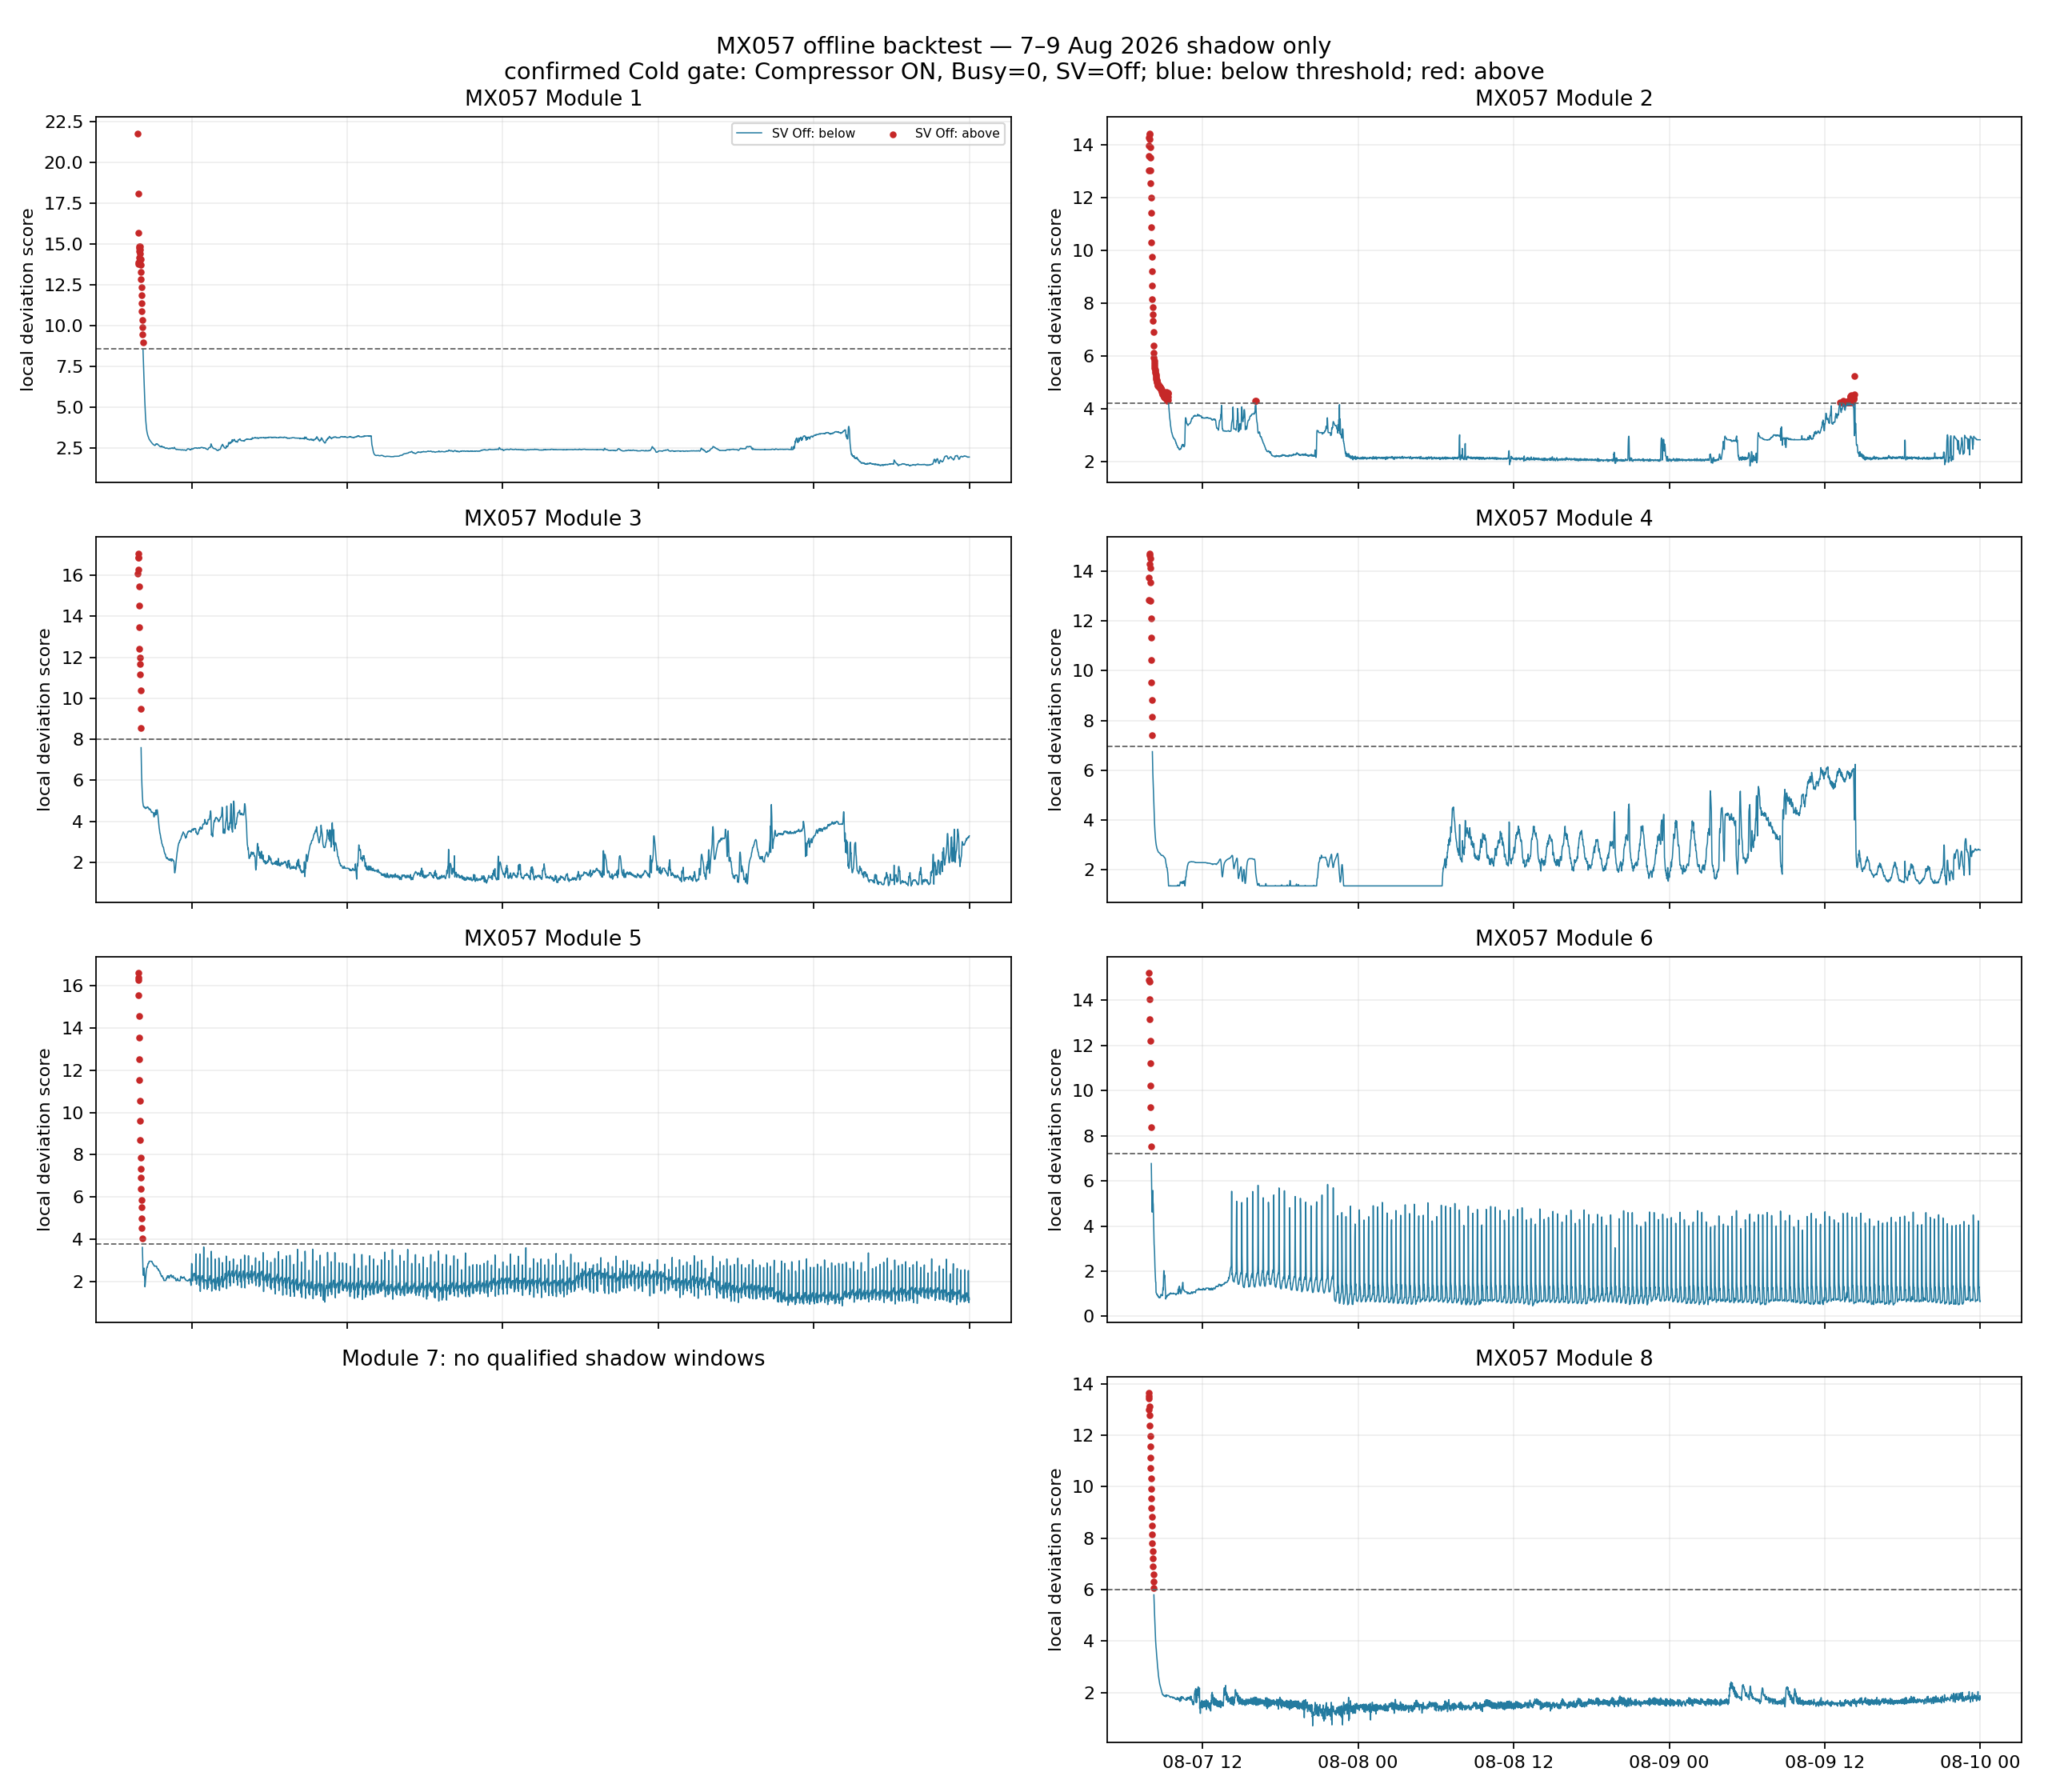

In [3]:
display(Image(filename=str(artifact / 'mx057_shadow_scores.png')))

## Takeaways

In [4]:
display(pd.Series(summary['profiles']).to_frame('value'))
display(profiles[['module','sv_state','state_code','status','reasons']])
print('Interpretation: only the owner-confirmed Cold state is eligible. No approval dry-run is an activation. Before Server staging, source machine_number × recorded_at must be unique; the worker fails closed if it is not.')

,value
total,7
by_status,"{'CANDIDATE_PROFILE': 5, 'REVIEW_REQUIRED': 2}"
approval_dry_run_eligible,0


,module,sv_state,state_code,status,reasons
0,1,Off,COMPRESSOR_ON_COLD_SV_OFF,REVIEW_REQUIRED,QUARANTINE_RATE_EXCEEDED;SHADOW_DURATION_LT_RE...
1,2,Off,COMPRESSOR_ON_COLD_SV_OFF,REVIEW_REQUIRED,SHADOW_DURATION_LT_REQUIRED;SHADOW_FLAG_RATE_E...
2,3,Off,COMPRESSOR_ON_COLD_SV_OFF,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED
3,4,Off,COMPRESSOR_ON_COLD_SV_OFF,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED
4,5,Off,COMPRESSOR_ON_COLD_SV_OFF,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED
5,6,Off,COMPRESSOR_ON_COLD_SV_OFF,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED
6,8,Off,COMPRESSOR_ON_COLD_SV_OFF,CANDIDATE_PROFILE,SHADOW_DURATION_LT_REQUIRED


Interpretation: only the owner-confirmed Cold state is eligible. No approval dry-run is an activation. Before Server staging, source machine_number × recorded_at must be unique; the worker fails closed if it is not.
